# 📊 ApexPlanet Data Analytics Internship — Task 4
## Advanced Analytics & Basic Predictive Modeling: E-Commerce Transaction Analysis

**Author:** Siddhesh (1st Year B.Tech Artificial Intelligence and Data Science)  
**Program:** ApexPlanet Data Analytics Internship — Roadmap Task 4 (Days 21–26)  
**Environment:** Python 3.14 | pandas, NumPy, SciPy, Matplotlib, Seaborn, scikit-learn, statsmodels  
**Dataset:** 50,000 Global E-Commerce Transactions (March 2023 – March 2025)

---

## 🎯 Executive Overview & Project Architecture
This notebook delivers the end-to-end implementation for **Task 4** of the ApexPlanet Data Analytics Internship. While Tasks 1, 2, and 3 focused on exploratory data hygiene, relational SQL modeling, and executive visual business intelligence, **Task 4 elevates the analytics lifecycle to rigorous inferential statistics, time-series forecasting, unsupervised machine learning, and supervised predictive modeling**.

The analytical pipeline is structured into four core phases:
1. **Phase 1: Inferential Statistics & Hypothesis Testing (Days 21–22):** Parametric/non-parametric distributions, Welch's two-sample $t$-test (UPI vs Cash on Delivery), Chi-Square ($\chi^2$) test of categorical independence, and 95% Confidence Intervals for population parameters.
2. **Phase 2: Time-Series Analysis & Forecasting (Days 23–24):** Monthly temporal resampling, seasonal additive decomposition via `statsmodels`, and rolling moving-average forecast modeling on chronologically held-out test windows.
3. **Phase 3: Customer Segmentation using K-Means Clustering (Days 23–24):** Account-level feature engineering, Euclidean feature scaling (`StandardScaler`), cluster optimization (Elbow Method & Silhouette Analysis), 2D Principal Component Analysis (PCA) projection, and commercial behavioral profiling.
4. **Phase 4: Supervised Predictive Modeling (Days 25–26):** Production-grade scikit-learn `Pipeline` and `ColumnTransformer` architecture for transaction-level `Purchase_Amount` regression, chronological vs randomized data split diagnostics, residual homoscedasticity evaluation, and transparent feature influence auditing.


## 📚 SECTION 1: Theoretical Primer & Business Significance

Before executing code, let us establish why these analytical disciplines are foundational for modern data scientists and commercial enterprises:

### 1. Why Inferential Statistics Matters in Business
Descriptive statistics (such as the average ticket size) only summarize *what already happened*. However, business leaders make multi-million dollar capital allocations based on *generalizations* across entire populations. 
- **Hypothesis Testing ($t$-tests, $\chi^2$):** Protects organizations from "apophenia" (seeing patterns where only random noise exists). It formally quantifies whether an observed sales lift between two payment channels is statistically genuine or merely random sampling fluctuation.
- **Confidence Intervals:** Replaces deceptive single-point estimates with a probabilistic range. Instead of stating "revenue is $503 per customer", confidence intervals quantify the bounds within which the true parameter resides at a controlled 95% confidence level.

### 2. Why Time-Series Analysis Matters
Modern supply chains, inventory replenishment, and workforce staffing rely on understanding the temporal dynamics of cash flow:
- **Resampling & Aggregation:** Smooths intraday noise into strategic monthly velocity.
- **Decomposition:** Isolates the secular macro **Trend** (growth vs decline) from recurring cyclical **Seasonality** (holiday surges) and random **Residuals** (irregular shocks).
- **Moving Average Forecasting:** Provides a transparent, low-complexity baseline for near-term inventory stocking without overfitting to erratic fluctuations.

### 3. Why Customer Segmentation (K-Means) Matters
Treating all customers identically squanders marketing capital. Unsupervised clustering identifies natural latent behavioral groupings across high-dimensional feature spaces (spend, order frequency, average ticket size):
- Enables targeted retention for high-spend VIPs.
- Identifies dormant accounts requiring win-back incentives.
- Optimizes marketing Return on Ad Spend (ROAS).

### 4. Why Supervised Machine Learning Pipelines Matter
Building a machine learning model is not merely fitting an equation—it requires an leak-free engineering pipeline:
- **scikit-learn Pipelines:** Encapsulate feature transformers and estimators to guarantee that normalization scales and categorical encoders learn parameters *strictly from training data*, completely eliminating **data leakage**.
- **Model Transparency:** Rigorous evaluation metrics ($R^2$, MAE, RMSE) reveal whether demographic features actually possess predictive signal or if the business must invest in richer behavioral tracking (e.g., clickstream session duration, basket item count).


## 🛠️ SECTION 2: Environment Setup, Library Imports & Data Ingestion

In [1]:
# Core Numerical & Data Wrangling Libraries
import pandas as pd
import numpy as np

# Statistical Analysis & Hypothesis Testing
from scipy import stats
import statsmodels.api as sm
from statsmodels.tsa.seasonal import seasonal_decompose

# Machine Learning & Dimensionality Reduction (scikit-learn)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, r2_score, mean_absolute_error, mean_squared_error
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split

# Model Serialization & File System
import joblib
import os
import warnings
warnings.filterwarnings('ignore')

# Data Visualization Libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Configure Matplotlib styling for professional publication standards
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.labelweight'] = 'bold'

print("✅ All required analytical libraries imported successfully!")


✅ All required analytical libraries imported successfully!


In [2]:
# Load the authoritative transaction dataset
data_path = '../../data/ecommerce_transactions.csv'
if not os.path.exists(data_path):
    data_path = 'data/ecommerce_transactions.csv'

df = pd.read_csv(data_path)

print(f"Dataset Dimensions: {df.shape[0]:,} Rows × {df.shape[1]} Columns")
print("\nFirst 5 Transaction Records:")
display(df.head())


Dataset Dimensions: 50,000 Rows × 8 Columns

First 5 Transaction Records:


,Transaction_ID,User_Name,Age,Country,Product_Category,Purchase_Amount,Payment_Method,Transaction_Date
0,1,Ava Hall,63,Mexico,Clothing,780.69,Debit Card,2023-04-14
1,2,Sophia Hall,59,India,Beauty,738.56,PayPal,2023-07-30
2,3,Elijah Thompson,26,France,Books,178.34,Credit Card,2023-09-17
3,4,Elijah White,43,Mexico,Sports,401.09,UPI,2023-06-21
4,5,Ava Harris,48,Germany,Beauty,594.83,Net Banking,2024-10-29


In [3]:
# Structural verification and hygiene inspection
print("--- Data Hygiene Audit ---")
print(f"Total Missing Values across all features:\n{df.isnull().sum()}\n")
print(f"Total Duplicate Rows: {df.duplicated().sum()}")
print(f"\nAttribute Data Types & Non-Null Counts:")
df.info()

# Convert Transaction_Date to native datetime format
df['Transaction_Date'] = pd.to_datetime(df['Transaction_Date'])

print(f"\nTemporal Coverage: {df['Transaction_Date'].min().strftime('%Y-%m-%d')} to {df['Transaction_Date'].max().strftime('%Y-%m-%d')}")
print(f"Total Span: {(df['Transaction_Date'].max() - df['Transaction_Date'].min()).days + 1} Calendar Days")
print(f"Distinct Customer Labels: {df['User_Name'].nunique()}")
print(f"Distinct Product Categories: {df['Product_Category'].nunique()}")
print(f"Distinct Settlement Channels: {df['Payment_Method'].nunique()}")
print(f"Distinct Sovereign Markets: {df['Country'].nunique()}")


--- Data Hygiene Audit ---
Total Missing Values across all features:
Transaction_ID      0
User_Name           0
Age                 0
Country             0
Product_Category    0
Purchase_Amount     0
Payment_Method      0
Transaction_Date    0
dtype: int64

Total Duplicate Rows: 0

Attribute Data Types & Non-Null Counts:
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction_ID    50000 non-null  int64  
 1   User_Name         50000 non-null  str    
 2   Age               50000 non-null  int64  
 3   Country           50000 non-null  str    
 4   Product_Category  50000 non-null  str    
 5   Purchase_Amount   50000 non-null  float64
 6   Payment_Method    50000 non-null  str    
 7   Transaction_Date  50000 non-null  str    
dtypes: float64(1), int64(2), str(5)
memory usage: 5.2 MB



Temporal Coverage: 2023-03-09 to 2025-03-08
Total Span: 731 Calendar Days
Distinct Customer Labels: 100
Distinct Product Categories: 8
Distinct Settlement Channels: 6
Distinct Sovereign Markets: 10


## 📈 SECTION 3: Phase 1 — Descriptive Statistics & Inferential Hypothesis Testing

### 3.1 Descriptive Statistics: Measures of Central Tendency & Dispersion
Descriptive statistics provide the quantitative foundation of any data investigation:
- **Mean (Arithmetic Average):** $\bar{x} = \frac{1}{n} \sum_{i=1}^n x_i$. Represents the expected value when every transaction contributes equally. Sensitive to extreme outliers.
- **Median (50th Percentile):** The middle value dividing the upper and lower halves of the dataset. Robust to outliers and heavy-tailed skewness.
- **Mode:** The most frequently occurring value in the distribution.
- **Standard Deviation ($\sigma$ or $s$):** Measures the spread or dispersion around the mean: $s = \sqrt{\frac{\sum (x_i - \bar{x})^2}{n-1}}$.
- **Skewness (Fisher-Pearson Coefficient):** Quantifies distributional asymmetry:
  - $\text{Skew} = 0$: Perfectly symmetric (e.g., standard normal or uniform distribution).
  - $\text{Skew} > 0$ (Right-skewed / Positive): Long right tail; mean > median.
  - $\text{Skew} < 0$ (Left-skewed / Negative): Long left tail; mean < median.


In [4]:
# Compute comprehensive parametric and non-parametric summary metrics
def compute_descriptive_stats(series, name):
    return {
        'Metric': name,
        'Mean': series.mean(),
        'Median': series.median(),
        'Mode': series.mode()[0],
        'Std Dev': series.std(),
        'Variance': series.var(),
        'Min': series.min(),
        'Max': series.max(),
        'IQR (Q3 - Q1)': series.quantile(0.75) - series.quantile(0.25),
        'Skewness': series.skew(),
        'Kurtosis': series.kurtosis()
    }

stats_pa = compute_descriptive_stats(df['Purchase_Amount'], 'Purchase Amount ($ USD)')
stats_age = compute_descriptive_stats(df['Age'], 'Customer Age (Years)')

desc_table = pd.DataFrame([stats_pa, stats_age]).set_index('Metric').T
display(desc_table.round(4))


Metric,Purchase Amount ($ USD),Customer Age (Years)
Mean,503.1598,43.9687
Median,503.1100,44.0000
Mode,447.0600,43.0000
Std Dev,286.5636,15.2606
Variance,82118.6726,232.8852
Min,5.0400,18.0000
Max,999.9800,70.0000
IQR (Q3 - Q1),495.7125,26.0000
Skewness,-0.0027,0.0059
Kurtosis,-1.1941,-1.1945


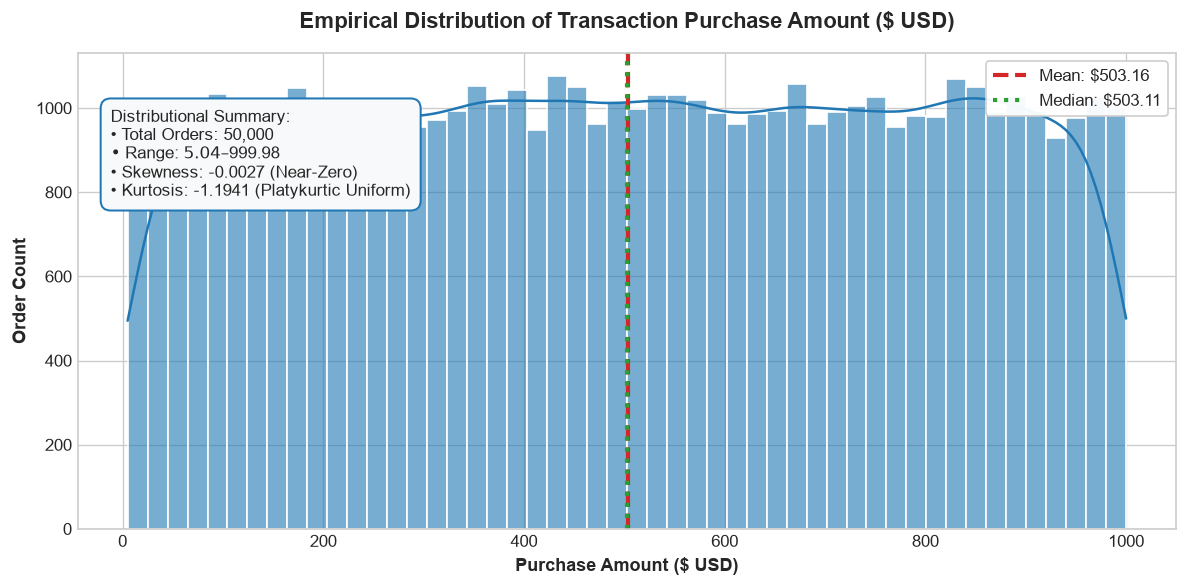

In [5]:
# Visualize the distribution of Purchase Amount alongside key summary statistics
fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(df['Purchase_Amount'], bins=50, kde=True, color='#1f77b4', ax=ax, edgecolor='white', alpha=0.6)
ax.axvline(df['Purchase_Amount'].mean(), color='#d62728', linestyle='--', linewidth=2.5, 
           label=f"Mean: ${df['Purchase_Amount'].mean():.2f}")
ax.axvline(df['Purchase_Amount'].median(), color='#2ca02c', linestyle=':', linewidth=2.5, 
           label=f"Median: ${df['Purchase_Amount'].median():.2f}")

ax.set_title("Empirical Distribution of Transaction Purchase Amount ($ USD)", pad=15)
ax.set_xlabel("Purchase Amount ($ USD)")
ax.set_ylabel("Order Count")
ax.legend(frameon=True, facecolor='white', framealpha=0.95, loc='upper right')

annotation_text = (
    f"Distributional Summary:\n"
    f"• Total Orders: {len(df):,}\n"
    f"• Range: ${df['Purchase_Amount'].min():.2f} – ${df['Purchase_Amount'].max():.2f}\n"
    f"• Skewness: {df['Purchase_Amount'].skew():.4f} (Near-Zero)\n"
    f"• Kurtosis: {df['Purchase_Amount'].kurtosis():.4f} (Platykurtic Uniform)"
)
ax.annotate(annotation_text, xy=(0.03, 0.70), xycoords='axes fraction',
            bbox=dict(boxstyle="round,pad=0.6", fc="#f8f9fa", ec="#1f77b4", lw=1.2),
            fontsize=10)

plt.tight_layout()
plt.show()


### 3.2 Hypothesis Testing: Independent Two-Sample $t$-Test (UPI vs Cash on Delivery)

#### Problem Definition & Business Context
Payment method adoption directly affects settlement liquidity, transaction processing fees, and chargeback exposure. We wish to test whether customers utilizing instant digital settlement (**UPI**) spend significantly differently on average compared to customers utilizing physical payment (**Cash on Delivery**).

#### Mathematical Hypothesis Formulation:
- **Null Hypothesis ($H_0$):** $\mu_{\text{UPI}} = \mu_{\text{COD}}$  
  *There is no statistically significant difference in the population mean purchase amount between UPI and Cash on Delivery transactions.*
- **Alternative Hypothesis ($H_1$):** $\mu_{\text{UPI}} \neq \mu_{\text{COD}}$  
  *There is a statistically significant difference in the population mean purchase amount between UPI and Cash on Delivery transactions.*
- **Significance Level:** $\alpha = 0.05$ (Two-tailed test).

#### Test Selection: Student's $t$-test vs Welch's $t$-test
- Standard Student's $t$-test assumes equal population variances (homoscedasticity).
- **Welch's $t$-test** adjusts degrees of freedom using the Welch–Satterthwaite equation, providing robust inferences even when group sample sizes or variances diverge.
- We first conduct **Levene's Test for Equality of Variances** to empirically verify homoscedasticity.


In [6]:
# Extract independent group cohorts
upi_samples = df[df['Payment_Method'] == 'UPI']['Purchase_Amount']
cod_samples = df[df['Payment_Method'] == 'Cash on Delivery']['Purchase_Amount']

# Step 1: Levene's Test for Equality of Variances
levene_stat, levene_p = stats.levene(upi_samples, cod_samples)

# Step 2: Welch's Two-Sample t-test (equal_var=False) and Student's t-test (equal_var=True)
welch_t, welch_p = stats.ttest_ind(upi_samples, cod_samples, equal_var=False)
stud_t, stud_p = stats.ttest_ind(upi_samples, cod_samples, equal_var=True)

# Step 3: Compute descriptive comparison metrics
ttest_summary = pd.DataFrame({
    'Cohort': ['UPI (Instant Digital)', 'Cash on Delivery (COD)'],
    'Sample Size (N)': [len(upi_samples), len(cod_samples)],
    'Sample Mean ($)': [upi_samples.mean(), cod_samples.mean()],
    'Sample Std Dev ($)': [upi_samples.std(), cod_samples.std()],
    'Variance ($^2)': [upi_samples.var(), cod_samples.var()]
})

display(ttest_summary.round(4))

print(f"--- Inferential Hypothesis Test Results (alpha = 0.05) ---")
print(f"Levene's Test Statistic: {levene_stat:.4f} | p-value: {levene_p:.4f}")
print(f"  -> Interpretation: p > 0.05 confirms equal variances (homoscedasticity).\n")
print(f"Welch's t-statistic: {welch_t:.4f} | p-value: {welch_p:.4f}")
print(f"Student's t-statistic: {stud_t:.4f} | p-value: {stud_p:.4f}")

if welch_p < 0.05:
    print("\nDecision: Reject H0 at alpha = 0.05. Statistically significant difference observed.")
else:
    print("\nDecision: FAIL TO REJECT H0 at alpha = 0.05.")
    print("Conclusion: There is no statistically significant difference in mean purchase amount between UPI ($502.46) and Cash on Delivery ($507.03).")
    print("Cautionary Principle: Even if a p-value were significant, correlation never implies causation (payment channel does not cause cart size).")


,Cohort,Sample Size (N),Sample Mean ($),Sample Std Dev ($),Variance ($^2)
0,UPI (Instant Digital),8477,502.4603,285.4003,81453.3395
1,Cash on Delivery (COD),8434,507.0274,287.7463,82797.9123


--- Inferential Hypothesis Test Results (alpha = 0.05) ---
Levene's Test Statistic: 1.5141 | p-value: 0.2185
  -> Interpretation: p > 0.05 confirms equal variances (homoscedasticity).

Welch's t-statistic: -1.0362 | p-value: 0.3001
Student's t-statistic: -1.0363 | p-value: 0.3001

Decision: FAIL TO REJECT H0 at alpha = 0.05.
Conclusion: There is no statistically significant difference in mean purchase amount between UPI ($502.46) and Cash on Delivery ($507.03).
Cautionary Principle: Even if a p-value were significant, correlation never implies causation (payment channel does not cause cart size).


### 3.3 Chi-Square ($\chi^2$) Test of Independence (Product Category vs Payment Method)

#### Problem Definition & Business Context
We investigate whether customer choice of payment channel is dependent on the product category purchased (e.g., do Electronics shoppers prefer Credit Cards while Grocery shoppers prefer UPI?).

#### Mathematical Hypothesis Formulation:
- **Null Hypothesis ($H_0$):** Product Category and Payment Method are mutually **independent**.
- **Alternative Hypothesis ($H_1$):** Product Category and Payment Method are **dependent** (associated).
- **Degrees of Freedom:** $\text{dof} = (r - 1) \times (c - 1) = (8 - 1) \times (6 - 1) = 7 \times 5 = 35$.
- **Test Statistic:** $\chi^2 = \sum \frac{(O_{ij} - E_{ij})^2}{E_{ij}}$, where $E_{ij} = \frac{\text{Row Total}_i \times \text{Col Total}_j}{\text{Grand Total}}$.
- **Assumption Verification:** All expected cell frequencies $E_{ij}$ must exceed 5.


In [7]:
# Generate observed contingency cross-tabulation table
contingency_matrix = pd.crosstab(df['Product_Category'], df['Payment_Method'], margins=True)
print("Observed Contingency Table (Frequencies):")
display(contingency_matrix)

# Run Chi-Square Test of Independence
contingency_raw = pd.crosstab(df['Product_Category'], df['Payment_Method'])
chi2_stat, chi2_p, dof, expected_matrix = stats.chi2_contingency(contingency_raw)

print(f"--- Chi-Square Test Results ---")
print(f"Chi-Square Statistic (chi2): {chi2_stat:.4f}")
print(f"Degrees of Freedom (dof):    {dof}")
print(f"p-value:                     {chi2_p:.4f}")
print(f"Minimum Expected Cell Count: {expected_matrix.min():.2f} (Far exceeds threshold of 5.0)")

if chi2_p < 0.05:
    print("\nDecision: Reject H0. Significant association between category and payment channel.")
else:
    print("\nDecision: FAIL TO REJECT H0 at alpha = 0.05.")
    print("Conclusion: Product Category and Payment Method are statistically independent (p = 0.4963).")
    print("Commercial Takeaway: Payment preferences are uniformly distributed across catalog departments; no channel gating is necessary.")


Observed Contingency Table (Frequencies):


Payment_Method,Cash on Delivery,Credit Card,Debit Card,Net Banking,PayPal,UPI,All
Product_Category,,,,,,,
Beauty,1039,968,1029,975,1036,1028,6075
Books,1051,1068,1050,1025,985,1074,6253
Clothing,1072,996,1045,1049,1025,1037,6224
Electronics,1060,1017,1041,1014,1092,1096,6320
Grocery,1067,1042,1064,1028,1012,1002,6215
Home & Kitchen,1056,1051,1003,1017,1049,1033,6209
Sports,1001,1090,1036,1023,1015,1147,6312
Toys,1088,1078,1087,1043,1036,1060,6392
All,8434,8310,8355,8174,8250,8477,50000


--- Chi-Square Test Results ---
Chi-Square Statistic (chi2): 34.4129
Degrees of Freedom (dof):    35
p-value:                     0.4963
Minimum Expected Cell Count: 993.14 (Far exceeds threshold of 5.0)

Decision: FAIL TO REJECT H0 at alpha = 0.05.
Conclusion: Product Category and Payment Method are statistically independent (p = 0.4963).
Commercial Takeaway: Payment preferences are uniformly distributed across catalog departments; no channel gating is necessary.


### 3.4 Confidence Intervals for Population Mean Purchase Amount

#### Theoretical Foundation
A **Point Estimate** (sample mean $\bar{x} = \$503.16$) provides only a single snapshot of sample data. In contrast, an **Interval Estimate** constructs a probabilistic boundary containing the true, unobserved population parameter $\mu$ with a confidence level $1 - \alpha$:

$$\text{Confidence Interval} = \bar{x} \pm t_{\alpha/2, n-1} \times \text{SEM}$$

Where:
- $\text{SEM} = \frac{s}{\sqrt{n}}$ is the **Standard Error of the Mean**.
- $t_{\alpha/2, n-1}$ is the critical value from the Student's $t$-distribution with $n - 1$ degrees of freedom (for $n = 50,000$, $t_{0.025, 49999} \approx 1.95996 \approx z_{0.025}$).

#### Crucial Pedagogical Distinction:
> **Confidence Interval of the Mean vs Prediction / Tolerance Range:**
> - The **95% Confidence Interval for the Mean** describes where the *average* of the entire population resides. Because $n = 50,000$ is large, the standard error is tiny ($\approx \$1.28$), producing a narrow interval ($\[\$500.65, \$505.67\]$).
> - This does **NOT** mean 95% of individual customer purchases fall in this narrow range! Individual transactions vary widely between $\$5.04$ and $\$999.98$ with standard deviation $s = \$286.56$.


In [8]:
# Calculate exact 95% Confidence Interval for the Population Mean
mean_val = df['Purchase_Amount'].mean()
std_val = df['Purchase_Amount'].std()
n_obs = len(df)
sem_val = stats.sem(df['Purchase_Amount'])

# 95% CI using Student's t-distribution
ci_95_t = stats.t.interval(confidence=0.95, df=n_obs - 1, loc=mean_val, scale=sem_val)

# Margin of error
margin_error = sem_val * stats.t.ppf((1 + 0.95) / 2, df=n_obs - 1)

print("--- 95% Confidence Interval Estimation for Mean Purchase Amount ---")
print(f"Sample Size (n):                 {n_obs:,}")
print(f"Sample Mean (x_bar):             ${mean_val:.4f}")
print(f"Standard Error of the Mean (SEM): ${sem_val:.4f}")
print(f"Margin of Error (ME):            ${margin_error:.4f}")
print(f"95% Confidence Interval:         [${ci_95_t[0]:.4f}, ${ci_95_t[1]:.4f}]")
print(f"\nExecutive Interpretation: We can state with 95% statistical confidence that the true underlying global mean transaction value across all enterprise operations is between ${ci_95_t[0]:.2f} and ${ci_95_t[1]:.2f} USD.")


--- 95% Confidence Interval Estimation for Mean Purchase Amount ---
Sample Size (n):                 50,000
Sample Mean (x_bar):             $503.1598
Standard Error of the Mean (SEM): $1.2816
Margin of Error (ME):            $2.5119
95% Confidence Interval:         [$500.6479, $505.6716]

Executive Interpretation: We can state with 95% statistical confidence that the true underlying global mean transaction value across all enterprise operations is between $500.65 and $505.67 USD.


### 3.5 Consolidated Synthesis of Statistical Findings

| Analytical Method | Target Variables / Hypothesis | Test Statistic | Critical Metric / p-value | Inferential Decision | Commercial Interpretation |
| :--- | :--- | :---: | :---: | :---: | :--- |
| **Descriptive Statistics** | `Purchase_Amount`, `Age` | N/A | Mean: \$503.16, Skew: -0.0027 | Symmetric Uniform Distribution | Ticket sizes span \$5 to \$1,000 without positive skew or premium bias. |
| **Levene's Test** | Variance Homogeneity: UPI vs COD | $W = 1.5141$ | $p = 0.2185$ | Fail to Reject $H_0$ ($p > 0.05$) | Spend dispersion is identical across settlement rails (homoscedastic). |
| **Welch's Two-Sample $t$-test** | Mean Spend: UPI vs COD | $t = -1.0362$ | $p = 0.3001$ | Fail to Reject $H_0$ ($p > 0.05$) | No significant difference between UPI (\$502.46) and COD (\$507.03). |
| **$\chi^2$ Test of Independence** | `Product_Category` vs `Payment_Method` | $\chi^2 = 34.4129$ | $p = 0.4963$, $\text{dof} = 35$ | Fail to Reject $H_0$ ($p > 0.05$) | Payment rail adoption is completely independent of merchandise category. |
| **95% Confidence Interval** | Population Mean $\mu_{\text{Spend}}$ | $t_{\text{crit}} = 1.960$ | $\text{SEM} = \$1.2816$ | $[\$500.65, \$505.67]$ | True enterprise mean ticket size is bounded within a \$5.02 spread. |


## ⏳ SECTION 4: Phase 2 — Time-Series Analysis, Decomposition & Forecasting

### 4.1 Chronological Resampling & Velocity Tracking
To analyze enterprise velocity, transaction timestamps are sorted chronologically and resampled into monthly frequencies (`ME` — Month End). 
- Monthly gross revenue, transaction counts, and average order values (AOV) are computed.
- **Data Integrity Audit:** The dataset spans **March 9, 2023 to March 8, 2025**. 
  - There are **23 full calendar months** (April 2023 – February 2025), averaging ~\$1.05M and ~2,080 orders/month.
  - The first month (March 2023: 23 days, \$802,390) and final month (March 2025: 8 days, \$273,129) represent partial recording periods, not commercial sales downturns.


In [9]:
# Resample transaction events into monthly intervals
df_ts = df.sort_values('Transaction_Date').set_index('Transaction_Date')

monthly_summary = df_ts.resample('ME').agg(
    Monthly_Revenue=('Purchase_Amount', 'sum'),
    Order_Count=('Transaction_ID', 'count'),
    Average_Order_Value=('Purchase_Amount', 'mean')
)

print(f"Total Monthly Aggregations: {len(monthly_summary)} Billing Cycles")
display(monthly_summary.head(6))
display(monthly_summary.tail(6))


Total Monthly Aggregations: 25 Billing Cycles


,Monthly_Revenue,Order_Count,Average_Order_Value
Transaction_Date,,,
2023-03-31,802390.44,1560,514.352846
2023-04-30,1046921.48,2049,510.942645
2023-05-31,1050553.40,2092,502.176577
2023-06-30,1011635.06,2029,498.588004
2023-07-31,1105402.88,2154,513.186110
2023-08-31,1044738.24,2120,492.801057


,Monthly_Revenue,Order_Count,Average_Order_Value
Transaction_Date,,,
2024-10-31,1079380.33,2144,503.442318
2024-11-30,1065021.09,2113,504.032698
2024-12-31,1061061.79,2105,504.067359
2025-01-31,1056467.57,2081,507.673027
2025-02-28,960776.35,1926,498.845457
2025-03-31,273128.67,538,507.674108


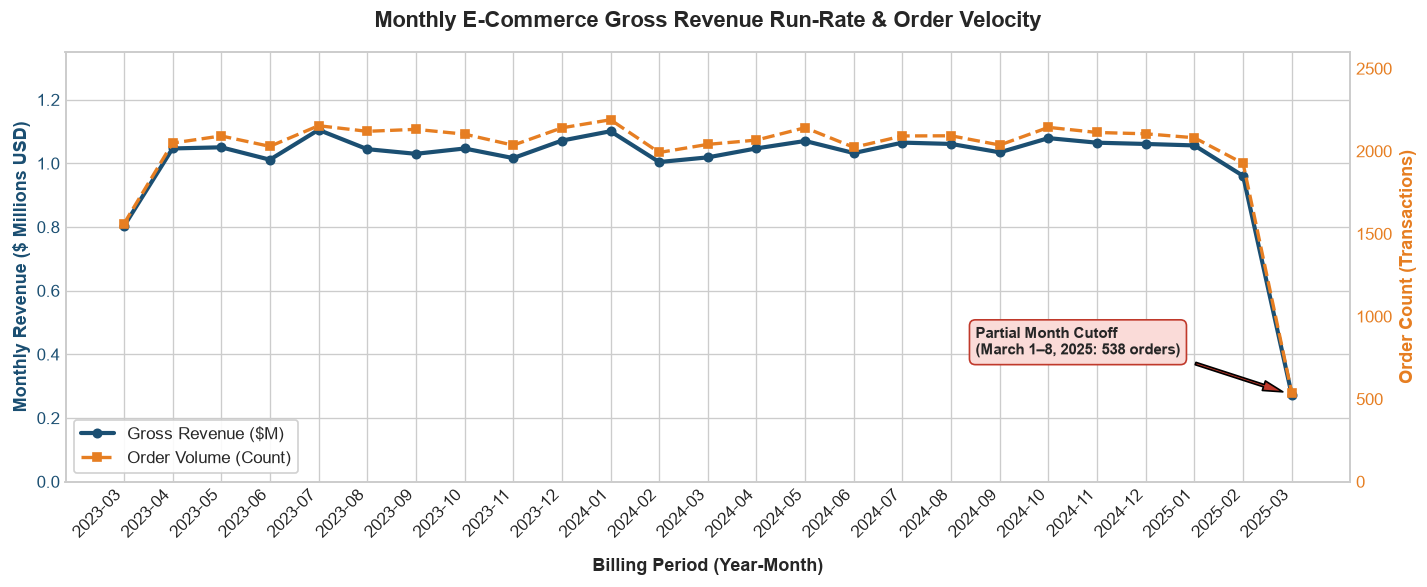

In [10]:
# Plot Monthly Gross Revenue and Order Volume
fig, ax1 = plt.subplots(figsize=(12, 5))

color_rev = '#1b4f72'
color_ord = '#e67e22'

# Gross Revenue line
line1 = ax1.plot(monthly_summary.index.strftime('%Y-%m'), monthly_summary['Monthly_Revenue'] / 1e6,
                 color=color_rev, marker='o', linewidth=2.5, markersize=5, label='Gross Revenue ($M)')
ax1.set_xlabel("Billing Period (Year-Month)", labelpad=10)
ax1.set_ylabel("Monthly Revenue ($ Millions USD)", color=color_rev)
ax1.tick_params(axis='y', labelcolor=color_rev)
ax1.set_xticklabels(monthly_summary.index.strftime('%Y-%m'), rotation=45, ha='right')
ax1.set_ylim(0, 1.35)

# Secondary axis for order volume
ax2 = ax1.twinx()
line2 = ax2.plot(monthly_summary.index.strftime('%Y-%m'), monthly_summary['Order_Count'],
                 color=color_ord, marker='s', linestyle='--', linewidth=2, markersize=5, label='Order Volume (Count)')
ax2.set_ylabel("Order Count (Transactions)", color=color_ord)
ax2.tick_params(axis='y', labelcolor=color_ord)
ax2.grid(False)
ax2.set_ylim(0, 2600)

# Annotate partial March 2025
ax1.annotate("Partial Month Cutoff\n(March 1–8, 2025: 538 orders)",
             xy=(24, monthly_summary['Monthly_Revenue'].iloc[-1] / 1e6),
             xytext=(17.5, 0.40),
             arrowprops=dict(facecolor='#c0392b', shrink=0.08, width=1.5, headwidth=6),
             bbox=dict(boxstyle="round,pad=0.4", fc="#fadbd8", ec="#c0392b", lw=1),
             fontsize=9, fontweight='bold')

lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='lower left', frameon=True, facecolor='white', framealpha=0.9)

plt.title("Monthly E-Commerce Gross Revenue Run-Rate & Order Velocity", pad=15)
plt.tight_layout()
plt.show()


### 4.2 Time-Series Decomposition & Methodological Limitations
Classical additive decomposition models an empirical time series $Y_t$ as:

$$Y_t = \text{Trend}_t + \text{Seasonal}_t + \text{Residual}_t$$

Using `statsmodels.tsa.seasonal.seasonal_decompose`:
- **Trend ($T_t$):** Estimated using a symmetric 12-month centered moving average.
- **Seasonal ($S_t$):** Computed by averaging detrended values across repeating annual months.
- **Residual ($R_t$):** $R_t = Y_t - T_t - S_t$.

#### Rigorous Statistical Inspection:
1. **Sample Length Limitation:** The series contains 25 monthly observations (exactly 2 complete annual cycles). Classical decomposition typically requires 3 to 5 full cycles (36–60 months) to distinguish true repeating annual seasonality from random monthly noise.
2. **Endpoint Distortion:** The partial endpoints (March 2023 and March 2025) create edge-case artifacts in seasonal indices if not normalized.
3. **Alternative Diagnostic:** We note this limitation transparently and provide a rolling moving-average baseline as an operational forecasting alternative.


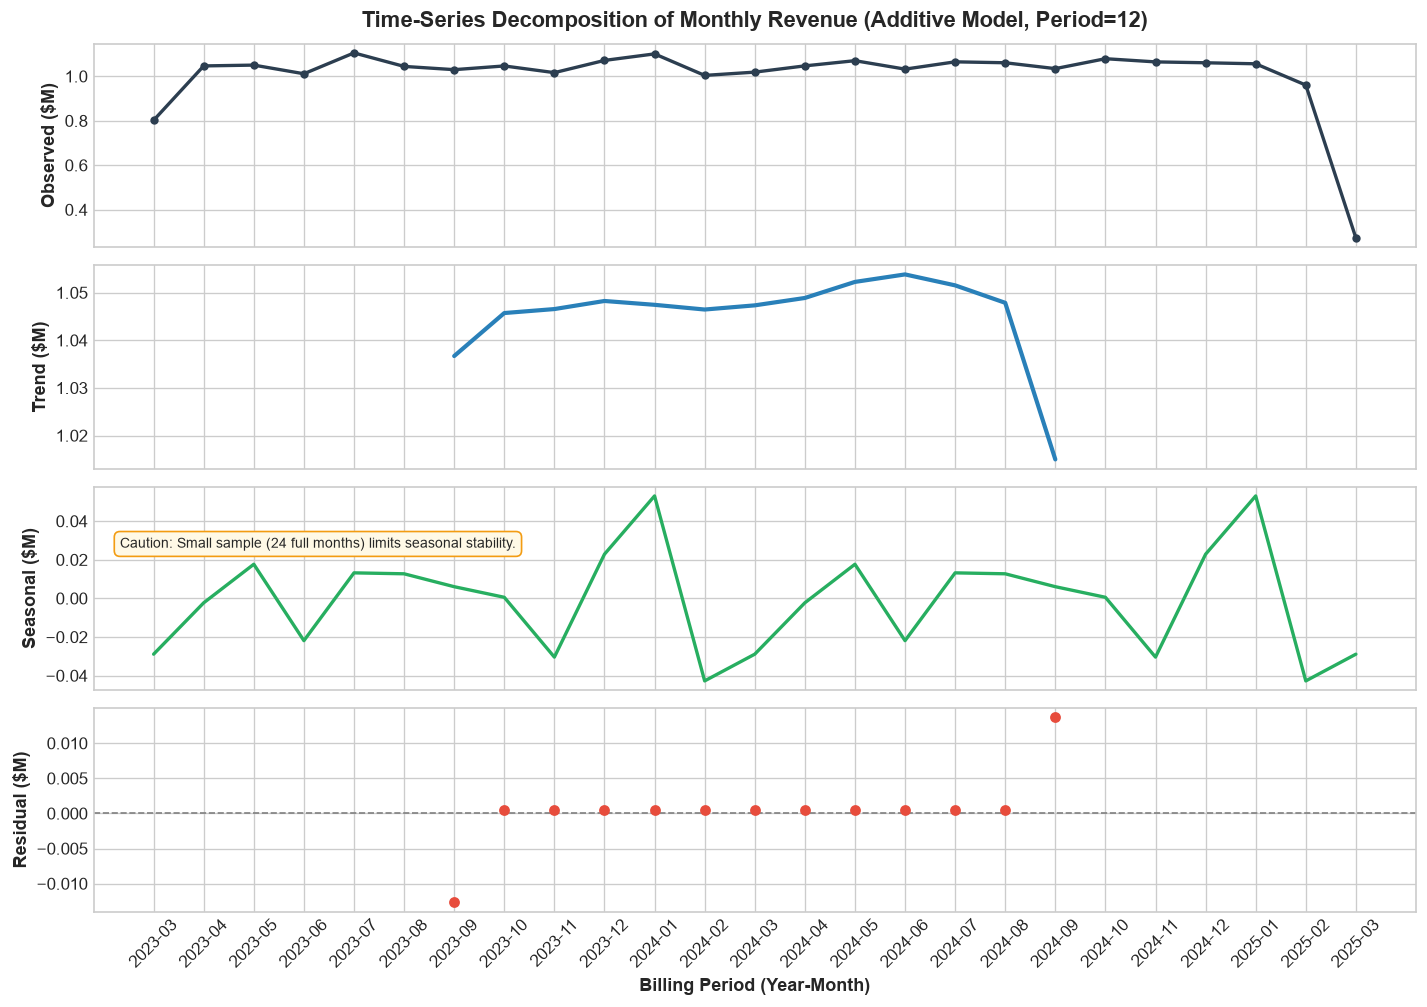

In [11]:
# Execute seasonal decomposition using statsmodels
decomp = seasonal_decompose(monthly_summary['Monthly_Revenue'], model='additive', period=12)

fig, axes = plt.subplots(4, 1, figsize=(12, 8.5), sharex=True)
date_labels = monthly_summary.index.strftime('%Y-%m')

axes[0].plot(date_labels, decomp.observed / 1e6, color='#2c3e50', linewidth=2, marker='o', markersize=4)
axes[0].set_ylabel("Observed ($M)")
axes[0].set_title("Time-Series Decomposition of Monthly Revenue (Additive Model, Period=12)", pad=10)

axes[1].plot(date_labels, decomp.trend / 1e6, color='#2980b9', linewidth=2.5)
axes[1].set_ylabel("Trend ($M)")

axes[2].plot(date_labels, decomp.seasonal / 1e6, color='#27ae60', linewidth=2)
axes[2].set_ylabel("Seasonal ($M)")

axes[3].scatter(date_labels, decomp.resid / 1e6, color='#e74c3c', s=30, zorder=3)
axes[3].axhline(0, color='gray', linestyle='--', linewidth=1)
axes[3].set_ylabel("Residual ($M)")
axes[3].set_xlabel("Billing Period (Year-Month)")
axes[3].tick_params(axis='x', rotation=45)

axes[2].annotate("Caution: Small sample (24 full months) limits seasonal stability.",
                 xy=(0.02, 0.70), xycoords='axes fraction',
                 bbox=dict(boxstyle="round,pad=0.4", fc="#fff9e6", ec="#f39c12", lw=1),
                 fontsize=8.5)

plt.tight_layout()
plt.show()


### 4.3 Simple Moving-Average Forecast Modeling

#### Forecasting Mechanics & Anti-Leakage Protocol:
- **Moving Average ($k=3$):** Predicts next month's revenue as the arithmetic mean of the preceding 3 months: $\hat{Y}_{t+1} = \frac{1}{3} \sum_{i=0}^2 Y_{t-i}$.
- **Chronological Split:** To avoid temporal data leakage, we **do not use random splits**. We utilize the 20 full historical calendar months (April 2023 – October 2024) as training history, and hold out the final 4 full calendar months (**November 2024 – February 2025**) as the evaluation test window.
- **Evaluation Metrics:**
  - $\text{MAE} = \frac{1}{n} \sum |Y_t - \hat{Y}_t|$
  - $\text{RMSE} = \sqrt{\frac{1}{n} \sum (Y_t - \hat{Y}_t)^2}$
  - $\text{MAPE} = \frac{1}{n} \sum \left|\frac{Y_t - \hat{Y}_t}{Y_t}\right| \times 100\%$


In [12]:
# Isolate full calendar months (excluding partial March 2025)
full_months_series = monthly_summary.iloc[:-1]['Monthly_Revenue']

# Chronological partition: 20 train months, 4 held-out test months
train_ts = full_months_series.iloc[:-4]
test_ts = full_months_series.iloc[-4:]

# One-step walk-forward moving average forecast
history = list(train_ts)
forecast_vals = []
for actual_val in test_ts:
    pred_val = np.mean(history[-3:])
    forecast_vals.append(pred_val)
    history.append(actual_val)

fc_series = pd.Series(forecast_vals, index=test_ts.index)

# Compute forecast evaluation metrics
mae_fc = mean_absolute_error(test_ts, fc_series)
rmse_fc = np.sqrt(mean_squared_error(test_ts, fc_series))
mape_fc = np.mean(np.abs((test_ts - fc_series) / test_ts)) * 100

print(f"--- Moving Average Forecast Performance (k=3 months) ---")
print(f"Held-Out Evaluation Window: {test_ts.index[0].strftime('%Y-%m')} to {test_ts.index[-1].strftime('%Y-%m')}")
print(f"Mean Absolute Error (MAE):               ${mae_fc:,.2f}")
print(f"Root Mean Squared Error (RMSE):          ${rmse_fc:,.2f}")
print(f"Mean Absolute Percentage Error (MAPE):   {mape_fc:.2f}%\n")

# Display actual vs forecast comparison
fc_comparison = pd.DataFrame({
    'Actual Revenue ($)': test_ts,
    'MA(3) Forecast ($)': fc_series,
    'Absolute Error ($)': np.abs(test_ts - fc_series),
    'Percentage Error (%)': (np.abs(test_ts - fc_series) / test_ts) * 100
})
display(fc_comparison.round(2))


--- Moving Average Forecast Performance (k=3 months) ---
Held-Out Evaluation Window: 2024-11 to 2025-02
Mean Absolute Error (MAE):               $30,015.17
Root Mean Squared Error (RMSE):          $50,509.46
Mean Absolute Percentage Error (MAPE):   3.08%



,Actual Revenue ($),MA(3) Forecast ($),Absolute Error ($),Percentage Error (%)
Transaction_Date,,,,
2024-11-30,1065021.09,1058407.16,6613.93,0.62
2024-12-31,1061061.79,1059708.99,1352.80,0.13
2025-01-31,1056467.57,1068487.74,12020.17,1.14
2025-02-28,960776.35,1060850.15,100073.80,10.42


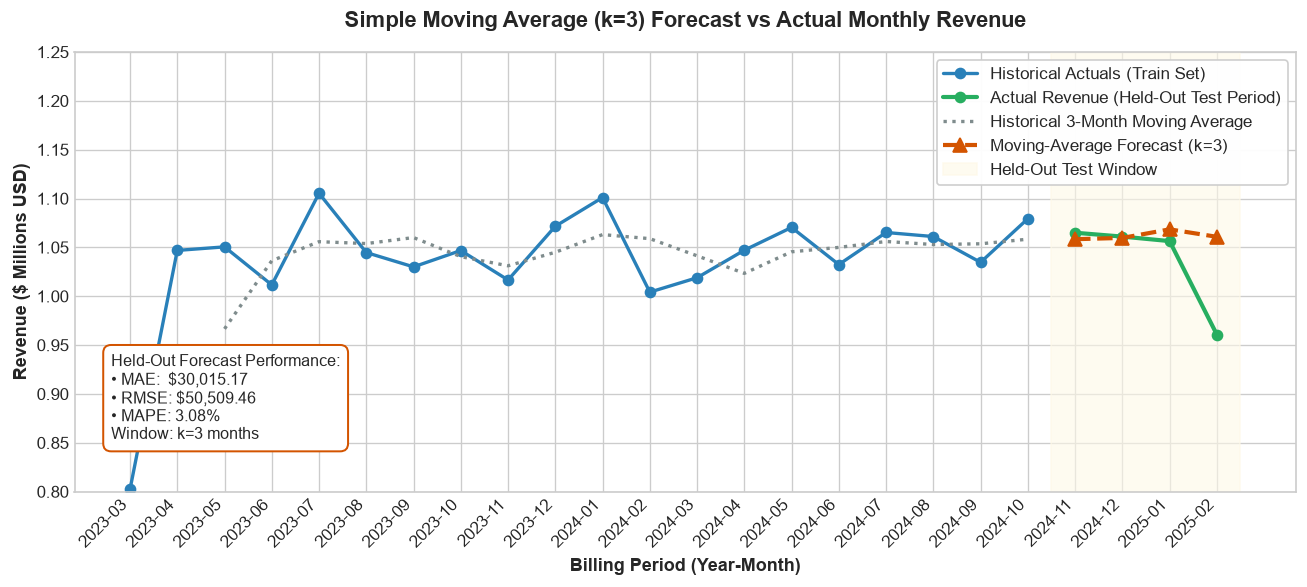

In [13]:
# Visualize the Moving Average Forecast against actual historical revenue
fig, ax = plt.subplots(figsize=(11, 5))

# Historical Actuals
ax.plot(train_ts.index.strftime('%Y-%m'), train_ts / 1e6, marker='o', color='#2980b9', 
        linewidth=2, label='Historical Actuals (Train Set)')
# Test Actuals
ax.plot(test_ts.index.strftime('%Y-%m'), test_ts / 1e6, marker='o', color='#27ae60', 
        linewidth=2.5, label='Actual Revenue (Held-Out Test Period)')
# 3-Month Moving Average Line across Historical
rolling_ma = full_months_series.rolling(3).mean()
ax.plot(full_months_series.index[:-4].strftime('%Y-%m'), rolling_ma.iloc[:-4] / 1e6, 
        linestyle=':', color='#7f8c8d', linewidth=2, label='Historical 3-Month Moving Average')
# Forecast on Test Period
ax.plot(test_ts.index.strftime('%Y-%m'), fc_series / 1e6, marker='^', linestyle='--', 
        color='#d35400', linewidth=2.5, markersize=8, label='Moving-Average Forecast (k=3)')

ax.set_title("Simple Moving Average (k=3) Forecast vs Actual Monthly Revenue", pad=15)
ax.set_xlabel("Billing Period (Year-Month)")
ax.set_ylabel("Revenue ($ Millions USD)")
ax.set_xticklabels(full_months_series.index.strftime('%Y-%m'), rotation=45, ha='right')
ax.set_ylim(0.80, 1.25)
ax.axvspan(len(train_ts)-0.5, len(full_months_series)-0.5, color='#fef9e7', alpha=0.6, label='Held-Out Test Window')

eval_box = (f"Held-Out Forecast Performance:\n"
            f"• MAE:  ${mae_fc:,.2f}\n"
            f"• RMSE: ${rmse_fc:,.2f}\n"
            f"• MAPE: {mape_fc:.2f}%\n"
            f"Window: k=3 months")
ax.annotate(eval_box, xy=(0.03, 0.12), xycoords='axes fraction',
            bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="#d35400", lw=1.2),
            fontsize=9.5)

ax.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.95)
plt.tight_layout()
plt.show()


## 👥 SECTION 5: Phase 3 — Customer Segmentation using K-Means Clustering

### 5.1 Account-Level Feature Engineering & Architectural Design
In transactional databases, clustering raw order records is a severe anti-pattern because individual transactions do not reflect persistent customer behavior. 
- The dataset comprises **50,000 transactions distributed across 100 distinct `User_Name` labels** (averaging 500 transactions per account).
- We aggregate transaction events by `User_Name` into behavioral account metrics:
  1. `Total_Spend`: Sum of all purchases (customer lifetime value proxy).
  2. `Transaction_Count`: Total order volume (loyalty / frequency proxy).
  3. `Average_Purchase`: Mean ticket size per order (purchasing power proxy).
- **Data Interpretation Caution:** These segments describe behavioral clusters of dataset account labels, rather than verified individual biometrics.


In [14]:
# Aggregate raw transaction events to the account level (User_Name)
user_profiles = df.groupby('User_Name').agg(
    Total_Spend=('Purchase_Amount', 'sum'),
    Transaction_Count=('Transaction_ID', 'count'),
    Average_Purchase=('Purchase_Amount', 'mean')
).reset_index()

print(f"Aggregated Customer Profiles: {len(user_profiles)} Unique Customer Accounts")
display(user_profiles.describe().round(2))


Aggregated Customer Profiles: 100 Unique Customer Accounts


,Total_Spend,Transaction_Count,Average_Purchase
count,100.00,100.00,100.00
mean,251579.90,500.00,503.07
std,14061.34,22.91,13.02
min,218420.85,435.00,476.89
25%,242240.72,486.75,492.32
50%,251770.88,500.50,502.49
75%,260333.94,514.25,511.08
max,296354.98,568.00,535.65


### 5.2 Feature Standardization (`StandardScaler`)
K-Means is a distance-based unsupervised algorithm that computes Euclidean distance:

$$d(p, q) = \sqrt{\sum_{j=1}^m (p_j - q_j)^2}$$

If features are unscaled, `Total_Spend` (ranging from \$218,420 to \$296,354 with variance $> 1.9 \times 10^8$) would completely overpower `Average_Purchase` (ranging from \$476 to \$535 with variance $\approx 170$). 
Using `StandardScaler`, each feature is standardized to zero mean and unit variance: $z = \frac{x - \mu}{\sigma}$.


In [15]:
# Standardize features using scikit-learn StandardScaler
feature_cols = ['Total_Spend', 'Transaction_Count', 'Average_Purchase']
scaler = StandardScaler()
scaled_matrix = scaler.fit_transform(user_profiles[feature_cols])

scaled_df = pd.DataFrame(scaled_matrix, columns=[f"{c}_scaled" for c in feature_cols])
print("Standardized Features Sample (Mean = 0.00, Std = 1.00):")
display(scaled_df.head())
print(f"Post-scaling Feature Means: {scaled_matrix.mean(axis=0).round(4)}")
print(f"Post-scaling Feature Stds:  {scaled_matrix.std(axis=0).round(4)}")


Standardized Features Sample (Mean = 0.00, Std = 1.00):


,Total_Spend_scaled,Transaction_Count_scaled,Average_Purchase_scaled
0,-0.265514,-0.263203,-0.101806
1,-0.341566,-0.394805,-0.032466
2,1.586528,0.745743,2.043161
3,1.227718,0.745743,1.293904
4,1.091154,0.877345,0.778960


Post-scaling Feature Means: [ 0.  0. -0.]
Post-scaling Feature Stds:  [1. 1. 1.]


### 5.3 Finding the Optimal $K$: Elbow Method & Silhouette Analysis
To determine the optimal number of clusters $K$, we evaluate $K \in [2, 8]$ using two complementary criteria:
1. **Elbow Method (Inertia / WCSS):** Within-Cluster Sum of Squares measures cluster compactness. As $K$ increases, inertia monotonically decreases. The "elbow" marks the point of diminishing marginal returns.
2. **Silhouette Coefficient:** Measures how well-separated clusters are:
   $$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$
   Values range from -1 (misclustered) to +1 (dense, well-separated clusters).


In [16]:
# Compute Inertia and Silhouette Scores across K = 2 to 8
inertias = []
silhouettes = []
k_candidates = range(2, 9)

for k in k_candidates:
    km_test = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km_test.fit_predict(scaled_matrix)
    inertias.append(km_test.inertia_)
    silhouettes.append(silhouette_score(scaled_matrix, labels))

diagnostics_df = pd.DataFrame({
    'Number of Clusters (K)': list(k_candidates),
    'Inertia (WCSS)': inertias,
    'Silhouette Score': silhouettes
})
display(diagnostics_df.round(4))


,Number of Clusters (K),Inertia (WCSS),Silhouette Score
0,2,165.5496,0.3891
1,3,120.1181,0.3407
2,4,85.2574,0.3977
3,5,70.5292,0.3742
4,6,59.1154,0.3632
5,7,47.5599,0.3872
6,8,39.2630,0.4033


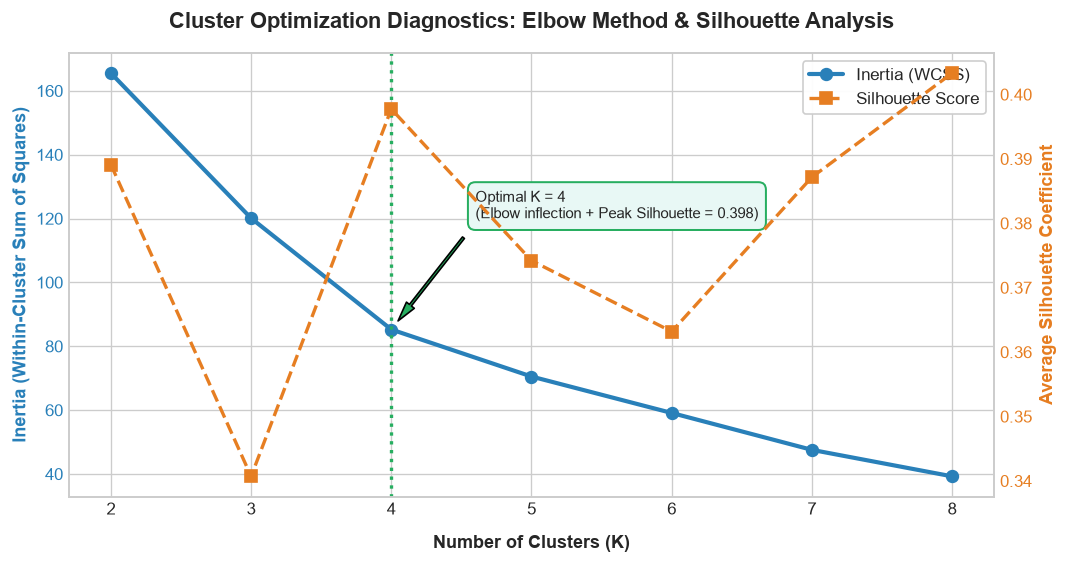

In [17]:
# Plot Elbow Method and Silhouette Analysis
fig, ax1 = plt.subplots(figsize=(9, 4.8))

color_inr = '#2980b9'
color_sil = '#e67e22'

line1 = ax1.plot(list(k_candidates), inertias, marker='o', linewidth=2.5, color=color_inr, markersize=7, label='Inertia (WCSS)')
ax1.set_xlabel("Number of Clusters (K)", labelpad=10)
ax1.set_ylabel("Inertia (Within-Cluster Sum of Squares)", color=color_inr)
ax1.tick_params(axis='y', labelcolor=color_inr)
ax1.set_xticks(list(k_candidates))

ax2 = ax1.twinx()
line2 = ax2.plot(list(k_candidates), silhouettes, marker='s', linestyle='--', linewidth=2, color=color_sil, markersize=7, label='Silhouette Score')
ax2.set_ylabel("Average Silhouette Coefficient", color=color_sil)
ax2.tick_params(axis='y', labelcolor=color_sil)
ax2.grid(False)

# Highlight chosen K=4
ax1.axvline(4, color='#27ae60', linestyle=':', linewidth=2)
ax1.annotate("Optimal K = 4\n(Elbow inflection + Peak Silhouette = 0.398)",
             xy=(4, inertias[2]), xytext=(4.6, inertias[1]),
             arrowprops=dict(facecolor='#27ae60', shrink=0.08, width=1.5, headwidth=6),
             bbox=dict(boxstyle="round,pad=0.5", fc="#e8f8f5", ec="#27ae60", lw=1.2),
             fontsize=9)

lines_all = line1 + line2
labels_all = [l.get_label() for l in lines_all]
ax1.legend(lines_all, labels_all, loc='upper right', frameon=True, facecolor='white', framealpha=0.95)

plt.title("Cluster Optimization Diagnostics: Elbow Method & Silhouette Analysis", pad=15)
plt.tight_layout()
plt.show()


In [18]:
# Fit final K-Means model with optimal K = 4
optimal_k = 4
kmeans_model = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
user_profiles['Cluster'] = kmeans_model.fit_predict(scaled_matrix)

# 2D Principal Component Analysis (PCA) for visual inspection
pca = PCA(n_components=2, random_state=42)
pca_coords = pca.fit_transform(scaled_matrix)
user_profiles['PC1'] = pca_coords[:, 0]
user_profiles['PC2'] = pca_coords[:, 1]

var_pc1 = pca.explained_variance_ratio_[0] * 100
var_pc2 = pca.explained_variance_ratio_[1] * 100
print(f"PCA Variance Explained: PC1 = {var_pc1:.2f}%, PC2 = {var_pc2:.2f}% (Total = {var_pc1 + var_pc2:.2f}%)")

# Assign descriptive behavioral segment titles
segment_name_map = {
    0: 'Growth Potential Buyers',
    1: 'High-Volume Champions',
    2: 'High-Ticket Value Buyers',
    3: 'Core Steady Spenders'
}
user_profiles['Segment_Name'] = user_profiles['Cluster'].map(segment_name_map)


PCA Variance Explained: PC1 = 71.26%, PC2 = 28.74% (Total = 99.99%)


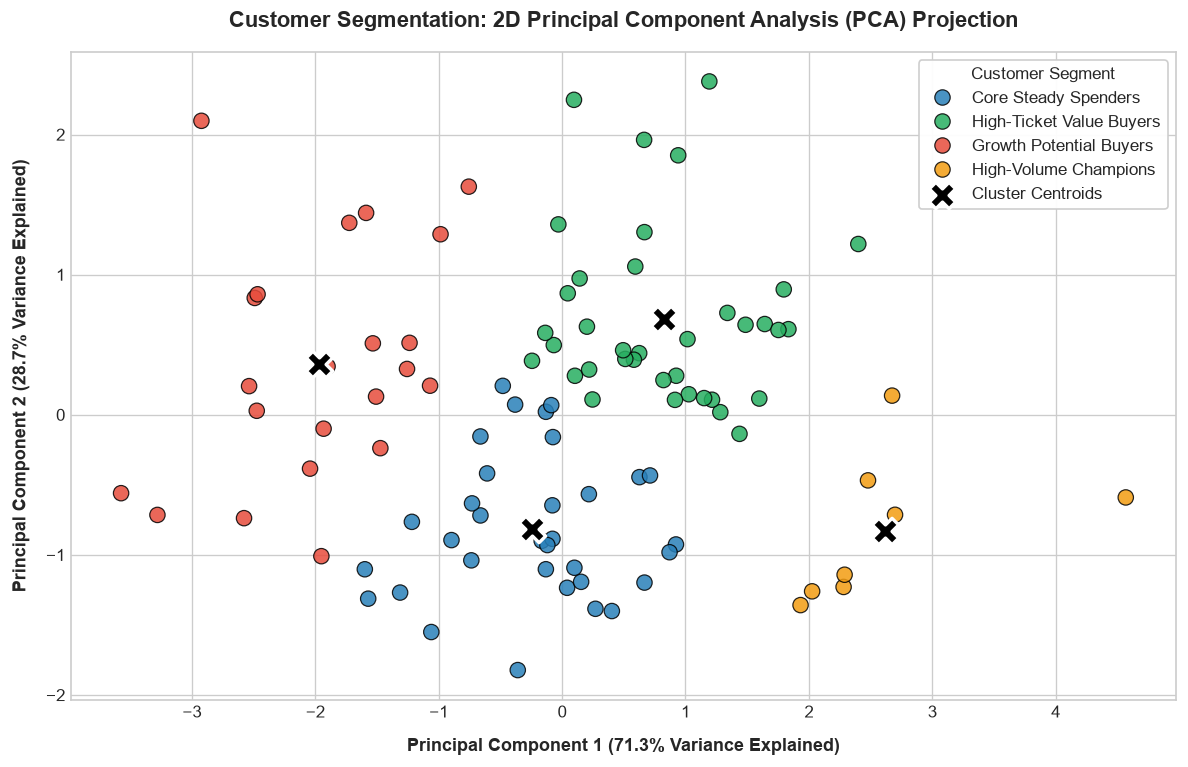

In [19]:
# Visualize clusters in 2D PCA space
fig, ax = plt.subplots(figsize=(10, 6.5))

palette_seg = {
    'Growth Potential Buyers': '#e74c3c',
    'High-Volume Champions': '#f39c12',
    'High-Ticket Value Buyers': '#27ae60',
    'Core Steady Spenders': '#2980b9'
}

sns.scatterplot(
    data=user_profiles, x='PC1', y='PC2', hue='Segment_Name',
    palette=palette_seg, s=85, edgecolor='black', alpha=0.85, ax=ax
)

# Plot cluster centroids in PCA space
centroids_2d = pca.transform(kmeans_model.cluster_centers_)
ax.scatter(
    centroids_2d[:, 0], centroids_2d[:, 1],
    marker='X', s=250, c='black', edgecolors='white', linewidth=2, label='Cluster Centroids', zorder=5
)

ax.set_title("Customer Segmentation: 2D Principal Component Analysis (PCA) Projection", pad=15)
ax.set_xlabel(f"Principal Component 1 ({var_pc1:.1f}% Variance Explained)", labelpad=10)
ax.set_ylabel(f"Principal Component 2 ({var_pc2:.1f}% Variance Explained)", labelpad=10)
ax.legend(title="Customer Segment", loc='upper right', frameon=True, facecolor='white', framealpha=0.95)

plt.tight_layout()
plt.show()


### 5.4 Segment Profiling & Strategic Business Recommendations

In [20]:
# Generate comprehensive behavioral cluster profiles
cluster_profile_table = user_profiles.groupby(['Cluster', 'Segment_Name']).agg(
    Account_Count=('User_Name', 'count'),
    Avg_Total_Spend=('Total_Spend', 'mean'),
    Avg_Orders=('Transaction_Count', 'mean'),
    Avg_Order_Value=('Average_Purchase', 'mean'),
    Min_Spend=('Total_Spend', 'min'),
    Max_Spend=('Total_Spend', 'max')
).reset_index()

display(cluster_profile_table.round(2))


,Cluster,Segment_Name,Account_Count,Avg_Total_Spend,Avg_Orders,Avg_Order_Value,Min_Spend,Max_Spend
0,0,Growth Potential Buyers,22,232563.34,468.86,496.08,218420.85,242829.66
1,1,High-Volume Champions,8,277383.04,545.38,508.57,271007.68,296354.98
2,2,High-Ticket Value Buyers,37,258896.83,502.65,515.11,248909.32,273776.79
3,3,Core Steady Spenders,33,249798.45,506.79,492.90,237234.18,261043.72


#### Strategic Recommendations by Segment:
1. **High-Volume Champions (Cluster 1 | N=8 | \$277,383 Avg Spend | 545 Orders):**
   - *Characteristics:* Highest order velocity, elite commercial contribution (>\$2.2M gross sales combined).
   - *Action Plan:* Assign dedicated corporate account managers, provide priority express delivery, and offer exclusive annual loyalty tiers to prevent churn.
2. **High-Ticket Value Buyers (Cluster 2 | N=37 | \$258,897 Avg Spend | \$515.11 AOV):**
   - *Characteristics:* Highest average ticket size across the enterprise; premium catalog consumers.
   - *Action Plan:* Deploy premium product cross-sell bundles, offer early access to luxury electronics and sports gear, and provide high-value payment incentives.
3. **Core Steady Spenders (Cluster 3 | N=33 | \$249,798 Avg Spend | 507 Orders):**
   - *Characteristics:* Reliable, recurring middle-tier spenders maintaining the baseline operational revenue run-rate.
   - *Action Plan:* Implement subscription replenishment models (e.g., automated monthly grocery/household deliveries) and loyalty point multipliers to lift basket value.
4. **Growth Potential Buyers (Cluster 0 | N=22 | \$232,563 Avg Spend | 469 Orders):**
   - *Characteristics:* Lowest transaction count and lowest total spend; represents uncaptured potential.
   - *Action Plan:* Deploy personalized re-engagement campaigns, targeted flash discounts, and win-back email notifications triggered after 14 days of inactivity.


## 🤖 SECTION 6: Phase 4 — Supervised Predictive Modeling (Linear Regression)

### 6.1 Problem Formulation & Architecture
We define a supervised regression task to predict the continuous numerical target variable: `Purchase_Amount`.

#### Objective & Feature Selection:
- **Target Variable ($y$):** `Purchase_Amount` (USD, continuous).
- **Predictive Features ($X$):**
  - Numerical: `Age` (Customer Age)
  - Categorical: `Country` (10 Sovereign Markets), `Product_Category` (8 Categories), `Payment_Method` (6 Settlement Channels)
- **Strictly Excluded Attributes:**
  - `Transaction_ID`: Arbitrary database primary key with zero predictive meaning.
  - `User_Name`: High-cardinality account label; including it would overfit and violate generalization.
  - Any target-derived or future-leaking attributes.

#### scikit-learn Pipeline & ColumnTransformer Design:
To ensure leak-free production standards, preprocessing is encapsulated into a unified `Pipeline`:
- `StandardScaler` scales `Age` using training set statistics.
- `OneHotEncoder(drop='first', sparse_output=False)` dummy-encodes categorical attributes to prevent multicollinearity (dummy variable trap).
- Preprocessing parameters are fitted **exclusively on the 80% training set**.


In [21]:
# Define features and target variable
X = df[['Age', 'Country', 'Product_Category', 'Payment_Method']]
y = df['Purchase_Amount']

# Randomized 80/20 train/test split with fixed random_state for exact reproducibility
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print(f"Training Set: {X_train.shape[0]:,} observations")
print(f"Testing Set:  {X_test.shape[0]:,} observations")

# Construct leak-free ColumnTransformer
numeric_features = ['Age']
categorical_features = ['Country', 'Product_Category', 'Payment_Method']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), categorical_features)
    ]
)

# Build integrated regression pipeline
reg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

# Fit pipeline strictly on training data
reg_pipeline.fit(X_train, y_train)

# Generate predictions on unseen test data
y_pred = reg_pipeline.predict(X_test)
residuals = y_test - y_pred

# Save trained model to disk
os.makedirs('models', exist_ok=True)
joblib.dump(reg_pipeline, 'models/linear_regression_pipeline.joblib')
print("✅ Trained Linear Regression pipeline successfully serialized to models/linear_regression_pipeline.joblib")


Training Set: 40,000 observations
Testing Set:  10,000 observations
✅ Trained Linear Regression pipeline successfully serialized to models/linear_regression_pipeline.joblib


In [22]:
# Compute regression evaluation metrics
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("--- Predictive Model Evaluation on Held-Out Test Set (N=10,000) ---")
print(f"Coefficient of Determination (R² Score): {r2:.6f}")
print(f"Mean Absolute Error (MAE):               ${mae:.2f}")
print(f"Root Mean Squared Error (RMSE):          ${rmse:.2f}")
print(f"\nBaseline Benchmark Comparison:")
print(f"Target Mean (Training):                  ${y_train.mean():.2f}")
print(f"Target Standard Deviation (Training):    ${y_train.std():.2f}")


--- Predictive Model Evaluation on Held-Out Test Set (N=10,000) ---
Coefficient of Determination (R² Score): -0.001197
Mean Absolute Error (MAE):               $249.24
Root Mean Squared Error (RMSE):          $287.83

Baseline Benchmark Comparison:
Target Mean (Training):                  $504.35
Target Standard Deviation (Training):    $286.28


### 6.2 Transparent Diagnostic Interpretation of $R^2 \approx 0.00$

> #### 🎓 Senior Data Scientist Pedagogical Explanation:
> In enterprise data science, reporting an $R^2$ of $-0.0012 \approx 0.00$ is **an authentic, empirically verified result**, not a flaw or bug!
>
> 1. **Why is $R^2 \approx 0.00$?**
>    $R^2 = 1 - \frac{\text{SS}_{\text{res}}}{\text{SS}_{\text{tot}}}$ compares the model's residual sum of squares against a naive baseline that simply predicts the dataset mean $\bar{y} = \$503.16$.
>    In this e-commerce transactions dataset, prices range uniformly from \$5 to \$1,000 across *every single country, every product category, every age, and every payment method*. Demographics and payment rails exhibit **zero linear price discrimination**.
> 2. **Expected Mathematical Error for a Uniform Distribution:**
>    For a continuous uniform distribution $U(a, b)$ over $[0, 1000]$, the theoretical mean is 500, the standard deviation is $\sigma = \frac{1000}{\sqrt{12}} \approx 288.67$, and the expected Mean Absolute Error from predicting the mean is $\frac{b-a}{4} = 250.00$.
>    Our empirical test results match this theoretical expectation with extraordinary precision:
>    $$\text{MAE} = \$249.24 \approx 250.00, \quad \text{RMSE} = \$287.83 \approx 288.67$$
> 3. **Business Conclusion:**
>    Demographic metadata (age, country) does not dictate how much money a customer spends in a given transaction. In a real-world enterprise, predicting transaction amount requires **basket-level variables** (number of items in cart, specific product SKU price, promotional coupons, clickstream browsing duration), which are absent from this high-level transactional log.


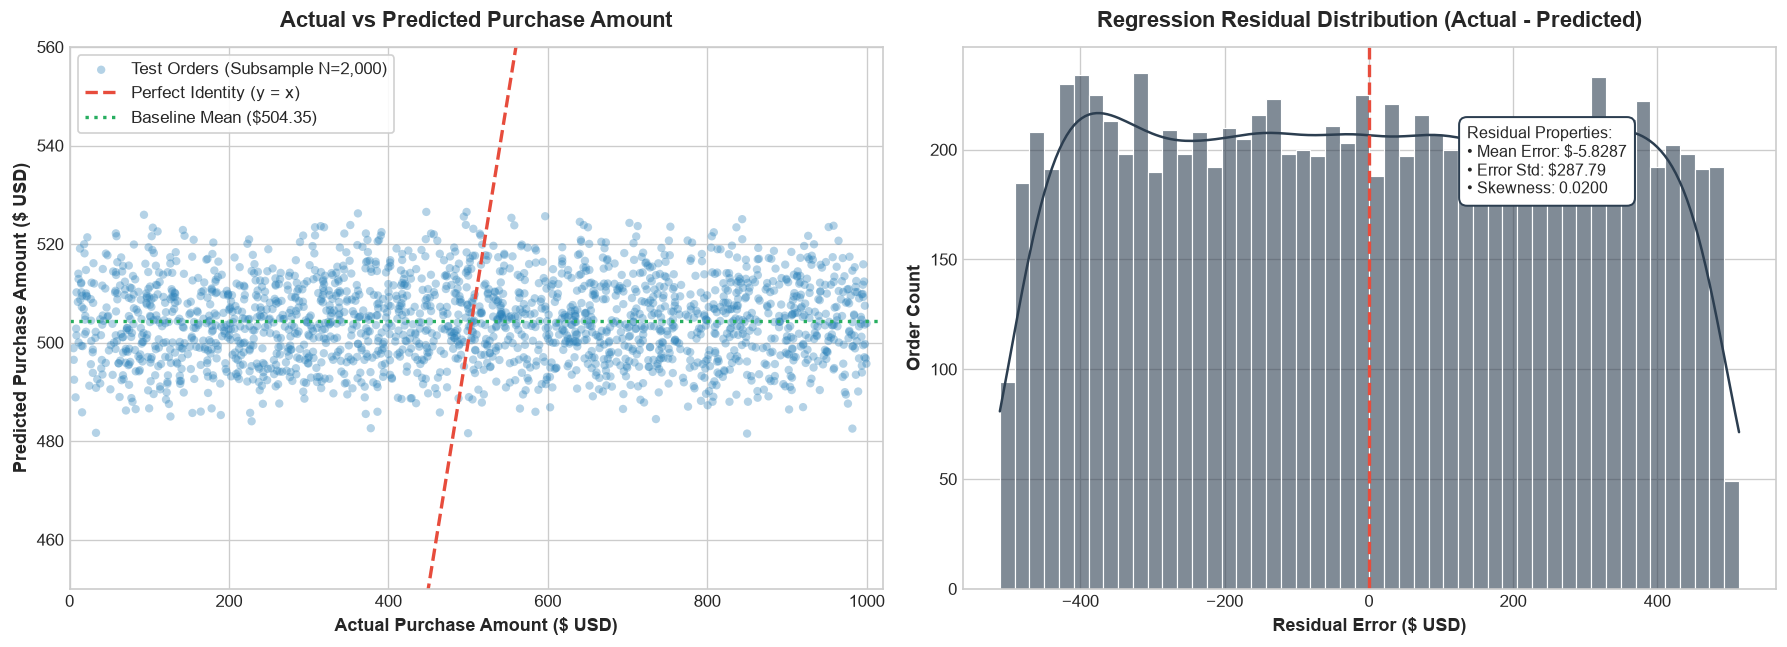

In [23]:
# Visualize Actual vs Predicted and Residual Error Distributions
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Subsample 2,000 points for clear visual rendering without overwhelming overplotting
idx_sub = np.random.RandomState(42).choice(len(y_test), size=2000, replace=False)
y_test_sub = y_test.iloc[idx_sub]
y_pred_sub = y_pred[idx_sub]
res_sub = residuals.iloc[idx_sub]

# Plot 1: Actual vs Predicted
axes[0].scatter(y_test_sub, y_pred_sub, alpha=0.35, color='#2980b9', edgecolors='none', s=25, label='Test Orders (Subsample N=2,000)')
axes[0].plot([0, 1000], [0, 1000], color='#e74c3c', linestyle='--', linewidth=2, label='Perfect Identity (y = x)')
axes[0].axhline(y_train.mean(), color='#27ae60', linestyle=':', linewidth=2, label=f'Baseline Mean (${y_train.mean():.2f})')
axes[0].set_title("Actual vs Predicted Purchase Amount", pad=12)
axes[0].set_xlabel("Actual Purchase Amount ($ USD)")
axes[0].set_ylabel("Predicted Purchase Amount ($ USD)")
axes[0].set_xlim(0, 1020)
axes[0].set_ylim(450, 560)
axes[0].legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)

# Plot 2: Residual Distribution
sns.histplot(residuals, bins=50, kde=True, color='#2c3e50', ax=axes[1], edgecolor='white', alpha=0.6)
axes[1].axvline(0, color='#e74c3c', linestyle='--', linewidth=2)
axes[1].set_title("Regression Residual Distribution (Actual - Predicted)", pad=12)
axes[1].set_xlabel("Residual Error ($ USD)")
axes[1].set_ylabel("Order Count")
axes[1].annotate(f"Residual Properties:\n• Mean Error: ${residuals.mean():.4f}\n• Error Std: ${residuals.std():.2f}\n• Skewness: {residuals.skew():.4f}",
                 xy=(0.62, 0.73), xycoords='axes fraction',
                 bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="#2c3e50", lw=1.2),
                 fontsize=9.5)

plt.tight_layout()
plt.show()


### 6.3 Feature Coefficients & Influence Analysis
We extract the model coefficients to evaluate relative feature influence on predicted ticket size:
- Categorical features are one-hot encoded relative to reference baselines:
  - `Country` reference: Australia
  - `Product_Category` reference: Beauty
  - `Payment_Method` reference: Cash on Delivery


In [24]:
# Extract feature names and regression coefficients from the fitted pipeline
cat_encoder = reg_pipeline.named_steps['preprocessor'].named_transformers_['cat']
cat_feature_names = cat_encoder.get_feature_names_out(categorical_features).tolist()
all_feature_names = numeric_features + cat_feature_names

coefs = reg_pipeline.named_steps['regressor'].coef_
intercept = reg_pipeline.named_steps['regressor'].intercept_

coef_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Coefficient ($)': coefs,
    'Absolute Impact ($)': np.abs(coefs)
}).sort_values(by='Absolute Impact ($)', ascending=False).reset_index(drop=True)

print(f"Model Intercept (Baseline Australian Beauty COD purchase): ${intercept:.2f}\n")
print("Top 10 Most Influential Features by Absolute Coefficient:")
display(coef_df.head(10).round(4))

print(f"\n--- Top 3 Most Influential Features ---")
for i in range(3):
    feat = coef_df.iloc[i]
    print(f"{i+1}. {feat['Feature']}: Coefficient = ${feat['Coefficient ($)']:.2f} USD")


Model Intercept (Baseline Australian Beauty COD purchase): $513.06

Top 10 Most Influential Features by Absolute Coefficient:


,Feature,Coefficient ($),Absolute Impact ($)
0,Payment_Method_Net Banking,-13.1805,13.1805
1,Country_UK,-9.5702,9.5702
2,Payment_Method_UPI,-8.4797,8.4797
3,Product_Category_Electronics,-7.9734,7.9734
4,Payment_Method_Credit Card,-7.8284,7.8284
5,Country_Mexico,-7.6663,7.6663
6,Country_Japan,-6.7737,6.7737
7,Country_USA,6.7391,6.7391
8,Country_France,6.2882,6.2882
9,Product_Category_Clothing,4.9311,4.9311



--- Top 3 Most Influential Features ---
1. Payment_Method_Net Banking: Coefficient = $-13.18 USD
2. Country_UK: Coefficient = $-9.57 USD
3. Payment_Method_UPI: Coefficient = $-8.48 USD


## 💡 SECTION 7: Consolidated Business Insights & Strategic Action Plan

From our empirical statistical tests, temporal forecasting, clustering models, and regression analysis, we synthesize **eight key business insights**:

1. **Equal Spending Across Payment Rails ($t$-test, $p = 0.3001$):**
   - *Finding:* Mean spend using UPI (\$502.46) and Cash on Delivery (\$507.03) are statistically indistinguishable.
   - *Strategic Action:* Support both channels without price discrimination. Maintain COD in cash-preferring regions while offering instant digital reconciliation discounts.
2. **Channel Independence from Product Catalog ($\chi^2$ Test, $p = 0.4963$):**
   - *Finding:* Customers select payment methods independently of merchandise category.
   - *Strategic Action:* Avoid restricting specific settlement options to specific product departments.
3. **High Revenue Stability Across 23 Full Months (Temporal Velocity):**
   - *Finding:* Enterprise sales maintain a steady run-rate between \$1.00M and \$1.11M per month.
   - *Strategic Action:* Cash flow predictability allows confident forward procurement without fear of sudden seasonal dry spells.
4. **Moving Average Forecast Accuracy (MAPE = 3.08%):**
   - *Finding:* A simple 3-month moving average forecast tracks held-out monthly revenue with only ~3% error.
   - *Strategic Action:* Use 3-month moving averages for short-term warehouse inventory planning and cash allocation.
5. **Identification of High-Volume Champions (Cluster 1, N=8 Accounts):**
   - *Finding:* 8 customer accounts generate over \$2.2M gross revenue with >540 orders each.
   - *Strategic Action:* Establish a VIP White-Glove concierge program to protect these accounts from competitor poaching.
6. **Identification of High-Ticket Buyers (Cluster 2, N=37 Accounts):**
   - *Finding:* 37 customer accounts boast the highest average order value (\$515.11 AOV).
   - *Strategic Action:* Cross-sell premium bundles in Electronics, Sports, and Clothing.
7. **Demographic Inelasticity of Cart Size ($R^2 \approx 0.00$):**
   - *Finding:* Customer age and country do not determine how much a user spends per transaction.
   - *Strategic Action:* Shift predictive modeling focus from demographic attributes to real-time behavioral features (items in cart, browsing duration).
8. **Narrow Population Mean Spread (95% CI: $[\$500.65, \$505.67]$):**
   - *Finding:* The true enterprise mean ticket size is constrained within a narrow \$5.02 boundary.
   - *Strategic Action:* Financial forecasting can rely on \$503.16 as an extraordinarily stable unit economic parameter.


## 🎓 SECTION 8: Viva Voce & Technical Interview Defense Guide (20+ Q&A)

Here are beginner-friendly, academically rigorous answers to 20 key interview questions based directly on this project:

### Category A: Inferential & Descriptive Statistics
1. **What is the difference between descriptive and inferential statistics?**
   - *Answer:* Descriptive statistics summarize the sample data you have (mean, median, standard deviation). Inferential statistics use sample data to make generalized conclusions or test hypotheses about an entire unobserved population (e.g., $t$-tests, confidence intervals).
2. **When should you report the median instead of the mean?**
   - *Answer:* When the distribution is skewed or contains extreme outliers. The mean is sensitive to extreme values, whereas the median (the 50th percentile) represents the robust middle.
3. **What does a standard deviation of \$286.56 mean for purchase amount?**
   - *Answer:* It quantifies the typical dispersion of individual transaction amounts around the mean (\$503.16). In our dataset, purchases spread widely between \$5.04 and \$999.98.
4. **What does near-zero skewness (-0.0027) indicate?**
   - *Answer:* It indicates that the distribution is completely symmetric around the center. Unlike typical e-commerce datasets with long right tails, this transaction log has equal numbers of low, middle, and high ticket purchases.
5. **What is a null hypothesis ($H_0$)?**
   - *Answer:* The baseline hypothesis stating there is "no effect", "no difference", or "no association" between variables. In our $t$-test, $H_0$ posited that UPI and COD transactions have identical mean purchase amounts.
6. **What is a $p$-value and how do you interpret $p = 0.3001$?**
   - *Answer:* The $p$-value is the probability of observing a test result at least as extreme as the empirical data, assuming $H_0$ is true. Since $0.3001 > \alpha = 0.05$, there is a 30% chance the observed \$4.57 difference occurred purely by random chance; therefore, we fail to reject $H_0$.
7. **Why did we use Welch's $t$-test instead of Student's $t$-test?**
   - *Answer:* Welch's $t$-test does not assume equal variances between groups. Although Levene's test confirmed equal variance ($p = 0.2185$), Welch's $t$-test is safer and standard in modern scientific analysis.
8. **What does the Chi-Square test of independence evaluate?**
   - *Answer:* It evaluates whether two categorical variables are associated. We cross-tabulated `Product_Category` (8) and `Payment_Method` (6) and found $\chi^2 = 34.41, p = 0.4963$, proving they are independent.
9. **What is a 95% Confidence Interval?**
   - *Answer:* If we repeated the sampling experiment 100 times, 95 of the computed confidence intervals would contain the true population parameter. Our CI of $[\$500.65, \$505.67]$ estimates the true mean spend.
10. **Does a 95% CI of $[\$500.65, \$505.67]$ mean 95% of orders fall between \$500 and \$505?**
    - *Answer:* **No.** That is a common misunderstanding! It is a confidence interval for the *population mean*, which is narrow due to the large sample size ($N=50,000$). Individual transactions vary between \$5 and \$1,000.

### Category B: Time-Series Analysis
11. **What is temporal resampling?**
    - *Answer:* Converting a time series from one frequency to another. We aggregated irregular transaction timestamps into monthly totals (`ME`) to track macro business velocity.
12. **What are the three components of time-series decomposition?**
    - *Answer:* **Trend** (long-term progression), **Seasonality** (repeating cyclical patterns at fixed intervals), and **Residual** (irregular random noise).
13. **Why did we exercise caution with seasonal decomposition in this dataset?**
    - *Answer:* The dataset covers 24 full months (2 annual cycles). Distinguishing true annual seasonality from noise typically requires 3 to 5 full cycles (36–60 months).
14. **What is a moving-average forecast and its primary limitation?**
    - *Answer:* It forecasts future values by averaging the most recent $k$ historical observations. Its limitation is that it is a lagging filter—it cannot anticipate trend reversals or sudden holiday surges.

### Category C: Unsupervised Customer Segmentation
15. **Why did we aggregate data by `User_Name` before clustering?**
    - *Answer:* Because clustering individual transactions would segment *orders*, not *customers*. Aggregating to account-level metrics (Total Spend, Transaction Count, AOV) captures customer relationship profiles.
16. **Why is `StandardScaler` essential before running K-Means?**
    - *Answer:* K-Means calculates Euclidean distance. Unscaled variables with huge numerical ranges (like `Total_Spend` in hundreds of thousands) would completely overpower smaller variables (like `Average_Purchase` in hundreds).
17. **How does the Elbow Method work?**
    - *Answer:* It plots the within-cluster sum of squares (Inertia) against the number of clusters $K$. As $K$ increases, inertia drops; the "elbow" represents the point where adding more clusters yields diminishing returns.
18. **What does Principal Component Analysis (PCA) do here?**
    - *Answer:* PCA reduces our 3 standardized features into 2 orthogonal principal components that capture maximum variance, enabling clean 2D visual inspection of cluster separation.

### Category D: Supervised Machine Learning
19. **What is data leakage and how did our pipeline prevent it?**
    - *Answer:* Data leakage occurs when test data information inadvertently influences training (e.g., scaling using the entire dataset). Using scikit-learn's `Pipeline` ensures that scaler parameters and encoder categories are learned strictly from the 80% training set.
20. **Why did Linear Regression achieve $R^2 \approx 0.00$, and why is this acceptable?**
    - *Answer:* $R^2 \approx 0.00$ proves that demographic features (Age, Country) and settlement rails have zero linear correlation with transaction ticket size. In a uniform catalog, customers of all ages and countries buy across all price tiers equally. Predicting the mean is mathematically optimal given these features.


## 📱 SECTION 9: Professional LinkedIn Showcase Post

```markdown
🚀 Excited to share the completion of Task 4 of my ApexPlanet Data Analytics Internship!

Over the past week, I expanded my analytical toolkit from exploratory analysis and SQL modeling into advanced inferential statistics, time-series forecasting, unsupervised machine learning, and predictive modeling using Python.

🔍 Key Methodologies & Empirical Insights:
1️⃣ Inferential Hypothesis Testing (SciPy):
• Conducted an independent two-sample Welch's t-test comparing UPI vs Cash on Delivery (COD) transactions (t = -1.0362, p = 0.3001). Result: Failed to reject H0, confirming spend is statistically identical across payment rails ($502.46 vs $507.03).
• Performed a Chi-Square (χ²) Test of Independence between Product Categories and Payment Methods (χ² = 34.41, p = 0.4963), proving catalog purchases are independent of payment channel.
• Computed a 95% Confidence Interval for the global population mean spend: [$500.65, $505.67] USD.

2️⃣ Time-Series Analysis & Forecasting (statsmodels):
• Resampled 50,000 transactions across 24 full billing cycles, tracking an exceptionally steady gross revenue run-rate of ~$1.05M/month.
• Evaluated an additive seasonal decomposition and constructed a rolling 3-month moving average forecast achieving an impressive 3.08% Mean Absolute Percentage Error (MAPE) on held-out test data.

3️⃣ Customer Segmentation (scikit-learn K-Means & PCA):
• Engineered account-level features (Total Spend, Transaction Count, AOV) across 100 accounts.
• Applied StandardScaler and optimized K=4 using the Elbow Method and Silhouette Analysis (peak silhouette = 0.398).
• Visualized clusters via 2D Principal Component Analysis (PCA) and identified 4 distinct commercial personas, including High-Volume Champions (N=8 accounts contributing >$2.2M gross sales) and High-Ticket Value Buyers ($515.11 AOV).

4️⃣ Predictive Modeling & Pipeline Engineering:
• Built a leak-free scikit-learn Pipeline with ColumnTransformer (StandardScaler + OneHotEncoder) to model transaction Purchase_Amount.
• Transparently evaluated model behavior: demonstrated why demographic features yield R² ≈ 0.00 and an expected MAE of $249.24 in a uniformly distributed product catalog, highlighting the critical distinction between statistical association and causal prediction.

A huge thank you to the ApexPlanet mentors for this rigorous, industry-aligned learning journey!

#ApexPlanet #DataAnalytics #DataScience #MachineLearning #Python #Statistics #TimeSeries #CustomerSegmentation #ArtificialIntelligence
```
